In [1]:
import pathlib
import sys
import os

# Hacky way to get to root package
if "notebooks" in os.getcwd():
    os.chdir("..")

In [2]:
%load_ext autoreload
%autoreload 2
    
import sys
from data_container import load_scouted_data
import pandas as pd
import plotly.express as px
pd.set_option('display.max_columns', None)

In [3]:
scouted_data = load_scouted_data()
scouted_data['Team and Robot'] = scouted_data['Team and Robot'].astype(str)
scouted_data

,Scouter Initials,Match Number,Team and Robot,Starting Position,No Show,autoCarrotO,autoCarrotCakeO,autoCarrotL1,autoCarrotL2,autoCarrotL3,autoCarrotCakeL1,autoCarrotCakeL2,autoCarrotCakeL3,telCarrotO,telCarrotCakeO,telCarrotL1,telCarrotL2,telCarrotL3,telCarrotCakeL1,telCarrotCakeL2,telCarrotCakeL3,Auto Cross Kitchen Line,Auto Robot Stuck or Astop in Auto?,Harvest Haul Carrots,Harvest Haul Carrot Cakes,Defended by opponent?,Opposing Zone Actions,Park,Mechanical Issue?,Died?,Tipped/Fell Over,Scoring Effectiveness,Defense Skill,Yellow/Red Card
0,abc,1,3484,Other,False,1,2,0,3,3,0,2,1,28,12,6,3,9,5,10,10,False,False,1,0,True,Collecting,True,True,False,False,2,3,No Card
1,abc,1,63,Middle Driver Station,False,0,2,4,1,2,0,0,1,28,4,10,19,23,12,12,16,False,False,3,0,True,Defense,True,False,False,False,1,3,No Card
2,abc,1,9406,Alliance Oven/Ramp,False,0,2,3,2,1,2,1,2,6,19,21,19,27,3,7,17,False,False,1,0,True,Defense,True,False,False,False,0,5,No Card
3,abc,1,3504,Alliance Pantry,False,5,1,3,0,2,2,2,1,9,12,25,8,11,9,10,1,False,False,1,0,True,Defense,True,True,False,True,4,3,No Card
4,abc,1,4467,Alliance Pantry,False,2,0,5,2,4,0,2,0,13,8,30,1,1,5,14,15,False,False,0,1,True,Defense,True,True,False,False,4,5,No Card
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,abc,33,4467,Alliance Pantry,False,1,1,3,3,3,0,1,1,23,2,25,2,27,9,4,4,False,False,3,1,True,Collecting,True,True,False,False,1,3,Yellow Card
164,abc,33,9642,Alliance Pantry,False,2,2,5,0,2,2,1,1,5,10,3,4,25,3,11,9,False,False,0,0,True,Collecting,True,False,False,False,2,5,No Card
165,abc,33,2095,Alliance Pantry,False,0,1,2,0,1,0,2,2,19,15,28,27,15,13,5,15,False,False,0,1,True,Collecting,True,False,False,False,4,4,No Card
166,abc,33,4028,Alliance Pantry,False,1,0,5,4,0,0,1,1,7,17,17,28,28,15,0,2,False,False,2,0,True,Defense,True,False,False,False,4,4,No Card


In [4]:
team_averages = scouted_data.groupby("Team and Robot").mean(numeric_only=True)
team_averages

,Match Number,No Show,autoCarrotO,autoCarrotCakeO,autoCarrotL1,autoCarrotL2,autoCarrotL3,autoCarrotCakeL1,autoCarrotCakeL2,autoCarrotCakeL3,telCarrotO,telCarrotCakeO,telCarrotL1,telCarrotL2,telCarrotL3,telCarrotCakeL1,telCarrotCakeL2,telCarrotCakeL3,Auto Cross Kitchen Line,Auto Robot Stuck or Astop in Auto?,Harvest Haul Carrots,Harvest Haul Carrot Cakes,Defended by opponent?,Park,Mechanical Issue?,Died?,Tipped/Fell Over,Scoring Effectiveness,Defense Skill
Team and Robot,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
10300,21.666667,0.000000,2.333333,1.333333,2.000000,3.000000,2.000000,1.000000,0.333333,1.000000,20.666667,10.000000,10.000000,17.666667,10.333333,9.333333,9.666667,1.000000,0.000000,0.000000,1.666667,0.333333,1.000000,1.000000,0.000000,0.000000,0.000000,2.666667,3.000000
10512,22.333333,0.000000,2.000000,1.000000,3.666667,1.666667,3.666667,0.666667,0.666667,0.333333,13.333333,8.000000,15.666667,17.333333,15.333333,11.666667,17.333333,8.333333,0.000000,0.000000,1.666667,0.666667,1.000000,1.000000,0.000000,0.000000,0.000000,2.666667,0.666667
10513,22.333333,0.333333,2.666667,1.000000,3.000000,2.666667,3.000000,0.000000,1.333333,0.333333,11.333333,15.333333,10.666667,16.666667,18.000000,16.000000,11.333333,10.000000,0.000000,0.000000,2.666667,0.666667,1.000000,1.000000,0.333333,0.000000,0.000000,2.000000,3.333333
10515,21.666667,0.000000,1.000000,0.333333,2.666667,2.000000,2.000000,1.000000,0.000000,1.333333,18.333333,9.333333,10.333333,20.666667,21.333333,7.666667,9.666667,10.000000,0.000000,0.000000,2.000000,0.666667,1.000000,1.000000,0.666667,0.333333,0.333333,3.666667,3.000000
10516,23.000000,0.000000,1.333333,1.666667,1.666667,3.000000,2.333333,1.666667,0.666667,0.333333,19.333333,6.000000,13.666667,14.666667,21.000000,5.333333,19.000000,14.333333,0.000000,0.000000,1.333333,0.666667,1.000000,1.000000,0.000000,0.000000,0.000000,2.333333,1.333333
10517,22.333333,0.000000,1.000000,1.333333,3.666667,2.666667,1.333333,1.333333,1.666667,1.000000,13.333333,9.333333,11.000000,23.000000,15.333333,5.333333,12.000000,6.333333,0.000000,0.000000,2.000000,0.666667,1.000000,1.000000,0.333333,0.000000,0.000000,1.666667,3.000000
10582,23.666667,0.000000,3.333333,1.000000,1.333333,2.666667,1.666667,0.666667,1.666667,0.666667,6.333333,13.333333,19.333333,10.666667,26.333333,16.333333,10.666667,16.000000,0.333333,0.000000,1.000000,1.000000,1.000000,0.666667,0.666667,0.000000,0.000000,0.000000,3.000000
11456,24.000000,0.000000,3.333333,1.000000,3.000000,1.000000,4.000000,1.000000,0.666667,1.000000,22.666667,14.333333,15.000000,16.000000,18.000000,12.333333,5.666667,7.000000,0.000000,0.000000,2.000000,0.333333,1.000000,1.000000,0.333333,0.000000,0.000000,1.333333,2.000000
117,17.500000,0.250000,1.750000,1.000000,3.000000,2.500000,3.250000,0.750000,1.250000,0.500000,9.000000,7.750000,9.250000,17.000000,19.000000,9.500000,8.000000,8.750000,0.000000,0.000000,1.250000,0.250000,1.000000,1.000000,0.500000,0.000000,0.000000,2.750000,2.500000


In [5]:

fig = px.scatter(team_averages, x="Tele Pantry Carrot Scoring", y="Auto Pantry Carrot Scoring", text=team_averages.index)

fig.update_traces(textposition="middle left")

fig

ValueError: Value of 'x' is not the name of a column in 'data_frame'. Expected one of ['Match Number', 'No Show', 'autoCarrotO', 'autoCarrotCakeO', 'autoCarrotL1', 'autoCarrotL2', 'autoCarrotL3', 'autoCarrotCakeL1', 'autoCarrotCakeL2', 'autoCarrotCakeL3', 'telCarrotO', 'telCarrotCakeO', 'telCarrotL1', 'telCarrotL2', 'telCarrotL3', 'telCarrotCakeL1', 'telCarrotCakeL2', 'telCarrotCakeL3', 'Auto Cross Kitchen Line', 'Auto Robot Stuck or Astop in Auto?', 'Harvest Haul Carrots', 'Harvest Haul Carrot Cakes', 'Defended by opponent?', 'Park', 'Mechanical Issue?', 'Died?', 'Tipped/Fell Over', 'Scoring Effectiveness', 'Defense Skill'] but received: Tele Pantry Carrot Scoring

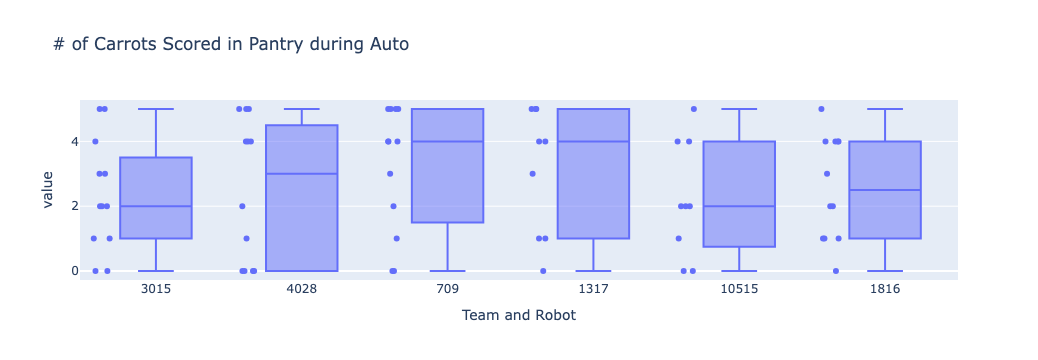

In [12]:
#L1, L2, L3 pantry carrot auto (box and whisker)
result = scouted_data[scouted_data["Team and Robot"].isin(["3015", "1317", "10515", "1816", "4028", "709"])]
fig = px.box(result, x="Team and Robot", y=["autoCarrotL1", "autoCarrotL2", "autoCarrotL3"], points="all", title="# of Carrots Scored in Pantry during Auto")
fig

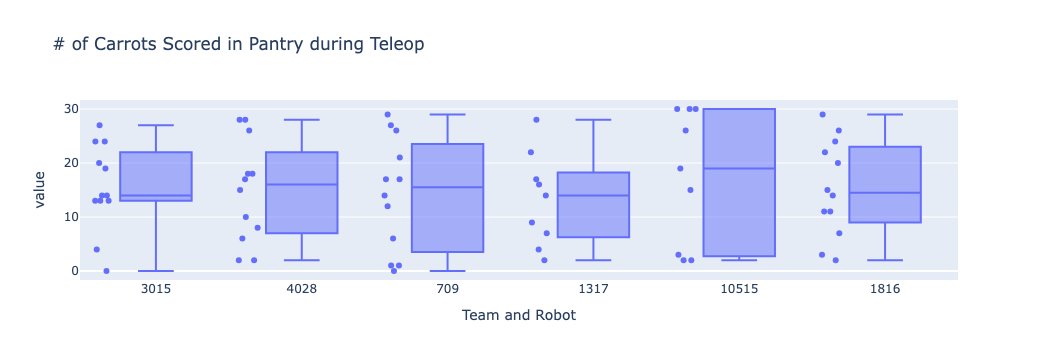

In [7]:
#L1, L2, L3 pantry carrot tele (box and whisker)
result = scouted_data[scouted_data["Team and Robot"].isin(["3015", "1317", "10515", "1816", "4028", "709"])]
fig = px.box(result, x="Team and Robot", y=["telCarrotL1", "telCarrotL2", "telCarrotL3"], points="all", title="# of Carrots Scored in Pantry during Teleop")
fig

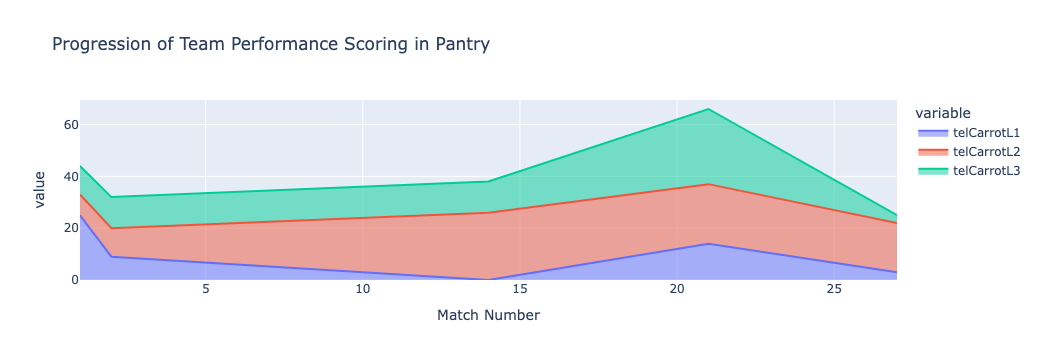

In [8]:
#Progress of one team scoring in L1, L2, L3 pantry over time (stacked scatter plot)

teamdata = scouted_data["Team and Robot"] == "3504"
indices = scouted_data[teamdata]
fig = px.area(indices, x="Match Number", y=["telCarrotL1", "telCarrotL2", "telCarrotL3"], title="Progression of Team Performance Scoring in Pantry")
fig

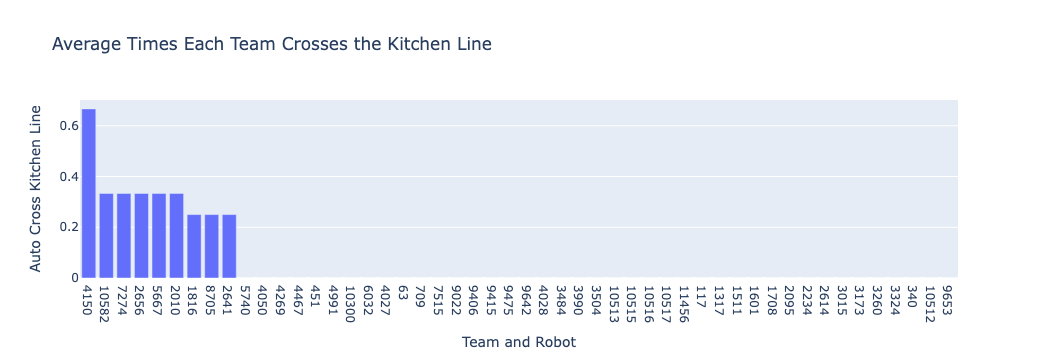

In [10]:
#Cross kitchen line (bar) #18

cross_averages = scouted_data.groupby("Team and Robot").mean(numeric_only=True).reset_index()
cross_averages = cross_averages.sort_values("Auto Cross Kitchen Line", ascending=False)

fig = px.bar(cross_averages, x="Team and Robot", y="Auto Cross Kitchen Line", title="Average Times Each Team Crosses the Kitchen Line")
fig

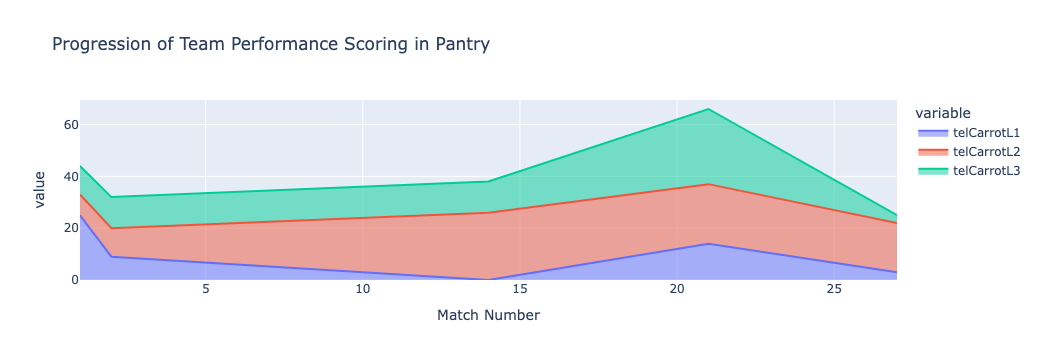

In [11]:
#Progress of one team scoring in L1, L2, L3 pantry over time (stacked scatter plot)

indices = scouted_data[teamdata]
teamdata = scouted_data["Team and Robot"] == "3504"
fig = px.area(indices, x="Match Number", y=["telCarrotL1", "telCarrotL2", "telCarrotL3"], title="Progression of Team Performance Scoring in Pantry")
fig

In [ ]:
#park, carrots, carrot cakes (stacked bar) #19

